# Rust Optimizer Fast-Paths

This notebook benchmarks every **optimizer-level** Rust fast-path in monod:

| Function / Flag | What it accelerates |
|---|---|
| `eval_kld_2d` | Single KLD evaluation from a unique histogram — no Python round-trip |
| `eval_kld_grad_2d` | KLD **+** full FD gradient in one parallel rayon call |
| `optimize_genes_2d_sd` | The complete L-BFGS-B loop for every gene of a Rust `SearchData`, genes in parallel under rayon — no scipy callbacks, no marshalling |
| `gradient_params["num_gene_cores"]` | Parallel scipy L-BFGS-B per gene via `ThreadPoolExecutor` |
| `gradient_params["use_rust_lbfgsb"]` | Route the inference pipeline's gene fits through the Rust optimizers (`optimize_genes_2d_sd` and its ambient, protein and custom-network variants) |

All benchmarks use synthetic data generated from a Bursty+None model so timings are reproducible without a specific dataset.

## Setup

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import importlib, subprocess, sys, os, pathlib
os.makedirs('figures', exist_ok=True)

def _try_run(*args):
    env = os.environ.copy()
    extra = [str(pathlib.Path.home() / ".cargo" / "bin"),
             str(pathlib.Path(sys.prefix) / "bin")]
    env["PATH"] = os.pathsep.join(extra) + os.pathsep + env.get("PATH", "")
    try:
        return subprocess.check_output(list(args), stderr=subprocess.DEVNULL,
                                       text=True, env=env).strip()
    except (FileNotFoundError, subprocess.CalledProcessError):
        return None

spec = importlib.util.find_spec("monod_core")
if spec is None:
    print("monod_core NOT found.  Build it with:")
    print("  cd monod_core && maturin develop --release")
    rust_ready = False
else:
    import monod_core as _mc
    print(f"monod_core : {_mc.__file__}")
    rustc = _try_run("rustc", "--version")
    print(f"rustc      : {rustc or 'not found (ok if extension already built)'}")
    rust_ready = True
    print("\nRust extension ready — all benchmarks will show Rust vs Python.")

monod_core : /home/coakes/miniconda3/envs/monod/lib/python3.11/site-packages/monod_core/__init__.py
rustc      : rustc 1.98.1 (48a229cea 2026-09-01)

Rust extension ready — all benchmarks will show Rust vs Python.


In [3]:
import sys, os, time, warnings
import numpy as np
import scipy.optimize
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from concurrent.futures import ThreadPoolExecutor


from monod.cme_toolbox import CMEModel, _HAS_RUST
warnings.filterwarnings("ignore")

# ── shared benchmark config ──────────────────────────────────────────────────
BIO_MODEL     = "Bursty"
FIXED_QUAD_T  = 10.0      # CMEModel's default quadrature horizon
QUAD_ORDER    = 10
FD_EPS        = 1e-6
LB = [-3.0, -3.0, -3.0]   # parameter bounds (log10)
UB = [ 3.0,  3.0,  3.0]
BOUNDS = list(zip(LB, UB))
EPS   = 1e-15

# ── colour scheme ────────────────────────────────────────────────────────────
C_PY   = "steelblue"
C_RUST = "firebrick"

print(f"_HAS_RUST = {_HAS_RUST}")

_HAS_RUST = True


In [4]:
# ── Synthetic gene factory ────────────────────────────────────────────────────
# Returns (u_idx, s_idx, f, limits) for a single gene.

def make_gene(p_log, limits, n_cells=3000, rng=None):
    """Sample n_cells observations from a Bursty model and return unique histogram."""
    if rng is None:
        rng = np.random.default_rng(0)
    pss = np.array(_mc.eval_model_pss_2d(BIO_MODEL, list(p_log), limits,
                                          FIXED_QUAD_T, QUAD_ORDER))
    flat = rng.choice(len(pss), size=n_cells, p=pss)
    ui   = (flat // limits[1]).astype(np.int64)
    si   = (flat  % limits[1]).astype(np.int64)
    pairs = np.column_stack([ui, si])
    up, cnt = np.unique(pairs, axis=0, return_counts=True)
    return (
        up[:, 0].astype(np.uint64).tolist(),
        up[:, 1].astype(np.uint64).tolist(),
        (cnt / n_cells).tolist(),
        [int(v) for v in limits],
    )

def make_sd(p_logs, limits, n_cells=3000, rng=None):
    """Sample n_cells cells for each gene in p_logs and build the Rust SearchData the
    inference pipeline hands to the optimizer.  Returns (sd, layers, coords, freqs)."""
    if rng is None:
        rng = np.random.default_rng(0)
    cols_u, cols_s = [], []
    for p_log in p_logs:
        pss = np.array(_mc.eval_model_pss_2d(BIO_MODEL, list(p_log), limits,
                                              FIXED_QUAD_T, QUAD_ORDER))
        flat = rng.choice(len(pss), size=n_cells, p=pss)
        cols_u.append(flat // limits[1]); cols_s.append(flat % limits[1])
    layers = [np.ascontiguousarray(np.column_stack(cols), dtype=np.int64) for cols in (cols_u, cols_s)]
    return sd_from_layers(layers, limits) + (layers,)

def sd_from_layers(layers, limits):
    """Rust SearchData from (n_cells, n_genes) count layers sharing one grid."""
    layers = [np.ascontiguousarray(x, dtype=np.int64) for x in layers]
    n_cells, n_genes = layers[0].shape
    coords, freqs = _mc.make_state_dist(layers)
    lim = np.ascontiguousarray(np.tile(np.asarray(limits, dtype=np.int64)[:, None], (1, n_genes)))
    sd = _mc.searchdata_from_arrays(layers, ["unspliced", "spliced"], lim, coords, freqs,
                                    [f"gene_{i}" for i in range(n_genes)], n_cells, "unique")
    return sd, coords, freqs

# Reference gene used in single-gene benchmarks
P_REF   = [-0.8, -0.5, -1.2]
LIMITS  = [24, 20]
rng0 = np.random.default_rng(7)
U_REF, S_REF, F_REF, LIM_REF = make_gene(P_REF, LIMITS, n_cells=5000, rng=rng0)

print(f"Reference gene: {len(F_REF)} unique microstates from 5 000 cells, grid {LIMITS[0]}×{LIMITS[1]}")

Reference gene: 47 unique microstates from 5 000 cells, grid 24×20


---
## 1  KLD Fast-Paths

Two Rust functions replace the Python path inside `CMEModel.eval_model_kld` and
`CMEModel.eval_model_kld_and_grad` whenever the model is 2-D, the histogram type
is `"unique"`, and the quadrature method is `"fixed_quad"`.

They activate **automatically** — no flag required.

```
Python path:  eval_model_pss_2d → Python indexing → np.sum(f * log(f/pss))
Rust path:    eval_kld_2d       → single C-extension call, no Python round-trip
```

### 1a  `eval_kld_2d`

Computes KLD(data ‖ model) for a unique histogram in one call.

In [5]:
# ── Correctness check ─────────────────────────────────────────────────────────
# Same quadrature as the Rust calls below, so the two paths are compared like for like.
model = CMEModel(BIO_MODEL, "None", fixed_quad_T=FIXED_QUAD_T, quad_order=QUAD_ORDER)

# Python path
pss_py   = model.eval_model_pss(np.array(P_REF), LIMITS)
np.clip(pss_py, EPS, None, out=pss_py)
x_arr    = np.column_stack([U_REF, S_REF]).astype(int)
f_arr    = np.array(F_REF)
kld_py   = float(np.sum(f_arr * np.log(f_arr / pss_py[x_arr[:, 0], x_arr[:, 1]])))

# Rust path
kld_rust = _mc.eval_kld_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                             FIXED_QUAD_T, QUAD_ORDER)

print(f"Python KLD : {kld_py:.8f}")
print(f"Rust   KLD : {kld_rust:.8f}")
print(f"Difference : {abs(kld_py - kld_rust):.2e}")

Python KLD : 0.00634565
Rust   KLD : 0.00634565
Difference : 3.47e-18


In [6]:
# ── Benchmark: eval_kld_2d ────────────────────────────────────────────────────
N_REPS = 500

t0 = time.perf_counter()
for _ in range(N_REPS):
    pss = model.eval_model_pss(np.array(P_REF), LIMITS)
    np.clip(pss, EPS, None, out=pss)
    _ = float(np.sum(f_arr * np.log(f_arr / pss[x_arr[:, 0], x_arr[:, 1]])))
t_py_kld = (time.perf_counter() - t0) / N_REPS * 1e3

t0 = time.perf_counter()
for _ in range(N_REPS):
    _ = _mc.eval_kld_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                         FIXED_QUAD_T, QUAD_ORDER)
t_ru_kld = (time.perf_counter() - t0) / N_REPS * 1e3

print(f"Python  eval_kld   : {t_py_kld:.3f} ms")
print(f"Rust    eval_kld_2d: {t_ru_kld:.3f} ms")
print(f"Speedup            : {t_py_kld / t_ru_kld:.1f}×")

Python  eval_kld   : 0.093 ms
Rust    eval_kld_2d: 0.026 ms
Speedup            : 3.6×


### 1b  `eval_kld_grad_2d`

Computes KLD **and** its finite-difference Jacobian in a single call.  All
`n_params + 1` PSS evaluations (base + one per parameter) run in parallel via
rayon with the GIL released.

In [7]:
# ── Correctness check ─────────────────────────────────────────────────────────
def py_kld_grad(p, limits, u_idx, s_idx, f):
    """Pure-Python finite-difference gradient (sequential)."""
    pss0 = model.eval_model_pss(np.asarray(p), limits)
    np.clip(pss0, EPS, None, out=pss0)
    x_a = np.column_stack([u_idx, s_idx]).astype(int)
    f_a = np.array(f)
    kld0 = float(np.sum(f_a * np.log(f_a / pss0[x_a[:, 0], x_a[:, 1]])))
    grad = []
    for i in range(len(p)):
        p_eps = list(p); p_eps[i] += FD_EPS
        pss_e = model.eval_model_pss(np.asarray(p_eps), limits)
        np.clip(pss_e, EPS, None, out=pss_e)
        kld_e = float(np.sum(f_a * np.log(f_a / pss_e[x_a[:, 0], x_a[:, 1]])))
        grad.append((kld_e - kld0) / FD_EPS)
    return kld0, grad

kld_py2, grad_py2   = py_kld_grad(P_REF, LIMITS, U_REF, S_REF, F_REF)
kld_ru2, grad_ru2   = _mc.eval_kld_grad_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                                             FIXED_QUAD_T, QUAD_ORDER, fd_eps=FD_EPS)

print(f"Python KLD  : {kld_py2:.8f}   grad = {[f'{g:.5f}' for g in grad_py2]}")
print(f"Rust   KLD  : {kld_ru2:.8f}   grad = {[f'{g:.5f}' for g in grad_ru2]}")
print(f"Max grad diff: {max(abs(a-b) for a,b in zip(grad_py2, grad_ru2)):.2e}")

Python KLD  : 0.00634565   grad = ['0.04437', '-0.00754', '-0.03383']
Rust   KLD  : 0.00634565   grad = ['0.04436', '-0.00781', '-0.03516']
Max grad diff: 1.33e-03


In [8]:
# ── Benchmark: eval_kld_grad_2d ───────────────────────────────────────────────
N_GRAD = 200

t0 = time.perf_counter()
for _ in range(N_GRAD):
    _ = py_kld_grad(P_REF, LIMITS, U_REF, S_REF, F_REF)
t_py_grad = (time.perf_counter() - t0) / N_GRAD * 1e3

t0 = time.perf_counter()
for _ in range(N_GRAD):
    _ = _mc.eval_kld_grad_2d(BIO_MODEL, P_REF, LIM_REF, U_REF, S_REF, F_REF,
                               FIXED_QUAD_T, QUAD_ORDER, fd_eps=FD_EPS)
t_ru_grad = (time.perf_counter() - t0) / N_GRAD * 1e3

print(f"Python  eval_kld_grad   : {t_py_grad:.3f} ms  (4 sequential PSS evals)")
print(f"Rust    eval_kld_grad_2d: {t_ru_grad:.3f} ms  (4 parallel  PSS evals, GIL released)")
print(f"Speedup                 : {t_py_grad / t_ru_grad:.1f}×")

Python  eval_kld_grad   : 0.362 ms  (4 sequential PSS evals)
Rust    eval_kld_grad_2d: 0.081 ms  (4 parallel  PSS evals, GIL released)
Speedup                 : 4.5×


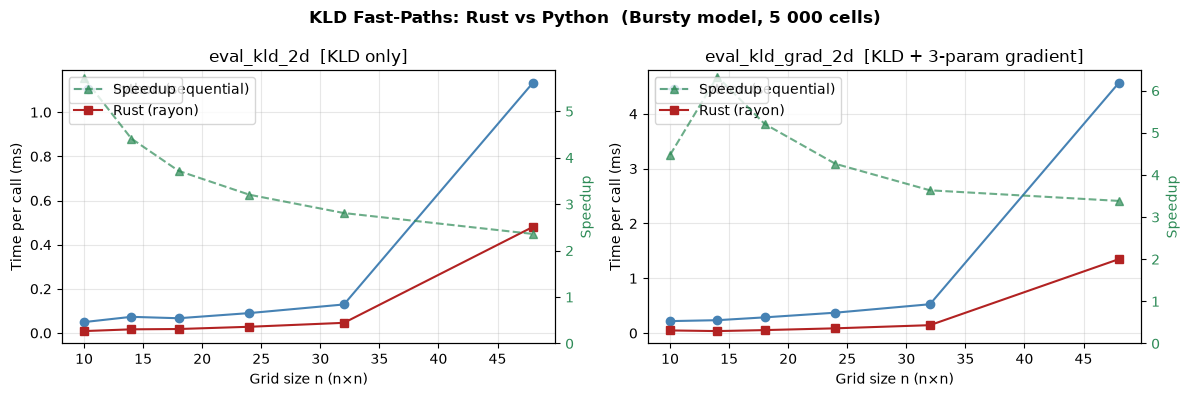

Saved kld_fastpaths.png


In [9]:
# ── Plot: KLD and KLD+grad speedup across grid sizes ─────────────────────────
grid_sizes = [10, 14, 18, 24, 32, 48]
py_kld_t, ru_kld_t, py_grad_t, ru_grad_t = [], [], [], []
N_G = 100

for gs in grid_sizes:
    lims = [gs, gs]
    u, s, f, lim = make_gene(P_REF, lims, n_cells=5000, rng=np.random.default_rng(0))
    x_a = np.column_stack([u, s]).astype(int)
    f_a = np.array(f)

    t0 = time.perf_counter()
    for _ in range(N_G):
        pss = model.eval_model_pss(np.array(P_REF), lims); np.clip(pss, EPS, None, out=pss)
        _ = float(np.sum(f_a * np.log(f_a / pss[x_a[:,0], x_a[:,1]])))
    py_kld_t.append((time.perf_counter()-t0)/N_G*1e3)

    t0 = time.perf_counter()
    for _ in range(N_G):
        _ = _mc.eval_kld_2d(BIO_MODEL, P_REF, lim, u, s, f, FIXED_QUAD_T, QUAD_ORDER)
    ru_kld_t.append((time.perf_counter()-t0)/N_G*1e3)

    t0 = time.perf_counter()
    for _ in range(N_G):
        _ = py_kld_grad(P_REF, lims, u, s, f)
    py_grad_t.append((time.perf_counter()-t0)/N_G*1e3)

    t0 = time.perf_counter()
    for _ in range(N_G):
        _ = _mc.eval_kld_grad_2d(BIO_MODEL, P_REF, lim, u, s, f, FIXED_QUAD_T, QUAD_ORDER)
    ru_grad_t.append((time.perf_counter()-t0)/N_G*1e3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, py_t, ru_t, title, note in [
    (axes[0], py_kld_t,  ru_kld_t,  "eval_kld_2d",      "KLD only"),
    (axes[1], py_grad_t, ru_grad_t, "eval_kld_grad_2d", "KLD + 3-param gradient"),
]:
    ax.plot(grid_sizes, py_t, 'o-', color=C_PY,   label="Python (sequential)")
    ax.plot(grid_sizes, ru_t, 's-', color=C_RUST,  label="Rust (rayon)")
    ax.set_xlabel("Grid size n (n×n)")
    ax.set_ylabel("Time per call (ms)")
    ax.set_title(f"{title}  [{note}]")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax2 = ax.twinx()
    ax2.plot(grid_sizes, [p/r for p,r in zip(py_t, ru_t)], '^--',
             color="seagreen", alpha=0.7, label="Speedup")
    ax2.set_ylabel("Speedup", color="seagreen")
    ax2.tick_params(axis='y', labelcolor='seagreen')
    ax2.set_ylim(bottom=0)
    ax2.legend(loc="upper left")

fig.suptitle("KLD Fast-Paths: Rust vs Python  (Bursty model, 5 000 cells)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.savefig("figures/kld_fastpaths.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved kld_fastpaths.png")

---
## 2  Rust L-BFGS-B

The Rust L-BFGS-B runs the **entire optimization loop** (L-BFGS two-loop recursion
+ More'-Thuente line search + box projection) in Rust with rayon outer
parallelism over genes.  `optimize_genes_2d_sd` reads the histograms straight
from a Rust `SearchData`, the container `searchdata_from_adata` builds, so there
are no Python callbacks, no GIL acquisition per optimizer iteration and no
marshalling of per-gene arrays.  Its ambient, protein and custom-network
variants share the solver.

The line search is a port of scipy's Fortran `dcsrch` (More'-Thuente, strong
Wolfe conditions); the search direction is the L-BFGS-B subspace step computed
with dense linear algebra, which is exact for the handful of parameters these
models have.  From the same start the two optimizers reach the same minimum;
the standalone solver tests in `monod_core/lbfgsb_rs_pure_patched/tests`
match scipy's iteration counts on Rosenbrock and quadratic problems.

A note on the status summary the optimizer logs: many genes end
with "stopped at the precision of the finite-difference gradient".  That is
the normal end point when the gradient is a forward difference, and the same
condition scipy reports as `ABNORMAL_TERMINATION_IN_LNSRCH`; the returned
point is the best one found.  Only genes that hit `max_iterations` are a
reason to raise it.

* The default since 0.4.0 (`gradient_params["use_rust_lbfgsb"] = "auto"`); `False` selects scipy.

### 2a  One gene

Replaces `scipy.optimize.minimize(..., method='L-BFGS-B')` with multiple restarts;
here on a one-gene `SearchData` holding the reference gene.

For a single gene this is not where the Rust solver wins: it computes each gene's
FD gradient sequentially inside one worker (the parallelism is over genes), while
the scipy loop below is driven by `eval_kld_grad_2d`, which spreads the
perturbations over rayon.  Section 2b is the case the solver is built for.

In [10]:
# ── API example: optimize_genes_2d_sd ─────────────────────────────────────────
#
#  params, klds = _mc.optimize_genes_2d_sd(
#      sd,                 # Rust SearchData (searchdata_from_adata / searchdata_from_arrays)
#      bio_model,          # "Bursty", "Constitutive", "CIR", "Extrinsic", "Delay", "DelayedSplicing"
#      x0_list,            # starting points, n_genes × num_restarts × n_params (log10)
#      lb, ub,             # box bounds (log10 scale), shared by all genes
#      fixed_quad_t,       # quadrature time scale
#      quad_order,         # number of GL quadrature points
#      fd_eps=1e-6,        # finite-difference step in log10 space
#      maxiter=1000,       # max L-BFGS-B iterations per restart
#      ftol=1e-10,         # relative function-improvement convergence
#      gtol=1e-6,          # projected gradient inf-norm convergence
#      base_samp=None,     # [log10_lam0, log10_lam1] for seq_model="Poisson"
#      eps=1e-15,          # probability floor
#      m_lbfgs=10,         # L-BFGS memory size
#      num_threads=None,   # rayon thread count; None = all cores
#      seq_model="Poisson",
#  ) -> (params: list[list[float]], klds: list[float])

X0_3 = [[-0.6, -0.4, -1.0], [0.0, 0.0, 0.0], [-1.5, -1.0, -1.5]]
SD_REF, _, _, _ = make_sd([P_REF], LIMITS, n_cells=5000, rng=np.random.default_rng(7))

(x_rust,), (kld_rust,) = _mc.optimize_genes_2d_sd(
    SD_REF, BIO_MODEL, [X0_3], LB, UB, FIXED_QUAD_T, QUAD_ORDER,
    fd_eps=FD_EPS, maxiter=500, ftol=1e-10, gtol=1e-6, seq_model="None",
)

print(f"Rust L-BFGS-B: kld = {kld_rust:.8f}")
print(f"               x   = {[f'{v:.4f}' for v in x_rust]}")
print(f"               true  = {P_REF}")


Rust L-BFGS-B: kld = 0.00622427
               x   = ['-0.8254', '-0.5214', '-1.2223']
               true  = [-0.8, -0.5, -1.2]


In [11]:
# ── Compare to scipy L-BFGS-B (same starting points, same FD gradient) ────────
def scipy_optimize_gene(u, s, f, limits, x0_list):
    """scipy L-BFGS-B with Rust KLD+grad callback."""
    best_kld, best_x = np.inf, None
    lim = [int(v) for v in limits]
    def obj_grad(p):
        kld, g = _mc.eval_kld_grad_2d(BIO_MODEL, list(p), lim, u, s, f,
                                       FIXED_QUAD_T, QUAD_ORDER, fd_eps=FD_EPS)
        return kld, np.array(g)
    for x0 in x0_list:
        res = scipy.optimize.minimize(obj_grad, x0, method="L-BFGS-B", jac=True,
                                      bounds=BOUNDS,
                                      options={"maxiter": 500, "ftol": 1e-10, "gtol": 1e-6})
        if res.fun < best_kld * 0.99:
            best_kld, best_x = res.fun, res.x
    return best_x, best_kld

x_sci, kld_sci = scipy_optimize_gene(U_REF, S_REF, F_REF, LIM_REF, X0_3)

print(f"scipy L-BFGS-B: kld = {kld_sci:.8f}")
print(f"                x   = {[f'{v:.4f}' for v in x_sci]}")
print(f"KLD difference: {abs(kld_rust - kld_sci):.2e}")

scipy L-BFGS-B: kld = 0.00622427
                x   = ['-0.8254', '-0.5214', '-1.2223']
KLD difference: 2.31e-16


In [12]:
# ── Speed benchmark ───────────────────────────────────────────────────────────
N_OPT = 30

t0 = time.perf_counter()
for _ in range(N_OPT):
    _ = _mc.optimize_genes_2d_sd(SD_REF, BIO_MODEL, [X0_3], LB, UB, FIXED_QUAD_T, QUAD_ORDER,
                                 fd_eps=FD_EPS, maxiter=500, seq_model="None", num_threads=1)
t_ru_opt = (time.perf_counter() - t0) / N_OPT * 1e3

t0 = time.perf_counter()
for _ in range(N_OPT):
    _ = scipy_optimize_gene(U_REF, S_REF, F_REF, LIM_REF, X0_3)
t_sci_opt = (time.perf_counter() - t0) / N_OPT * 1e3

print(f"Rust optimize_genes_2d_sd : {t_ru_opt:.2f} ms")
print(f"scipy L-BFGS-B            : {t_sci_opt:.2f} ms")
print(f"Speedup (single gene)     : {t_sci_opt/t_ru_opt:.2f}×")


Rust optimize_genes_2d_sd : 23.07 ms
scipy L-BFGS-B            : 16.97 ms
Speedup (single gene)     : 0.74×


### 2b  All genes at once (rayon)

One call optimizes every gene of the `SearchData` in parallel with rayon outer
parallelism.  Each gene's own FD gradient is computed sequentially within its
rayon worker (no nested rayon contention), giving near-linear scaling with CPU count.

In [13]:
# ── API example: all genes of a SearchData ────────────────────────────────────
N_GENES_DEMO = 20
rng_demo = np.random.default_rng(42)
# log10 (b, beta, gamma) drawn so that every gene's distribution fits the 24×20 grid
draw_params = lambda rng: [rng.uniform(-1.0, 0.3), rng.uniform(-0.5, 0.5), rng.uniform(-0.5, 0.5)]
p_trues = [draw_params(rng_demo) for _ in range(N_GENES_DEMO)]
SD_DEMO, _, _, _ = make_sd(p_trues, LIMITS, n_cells=3000, rng=np.random.default_rng(0))

x0_all = [[[0.0, 0.0, 0.0], [-1.0, -1.0, -1.0]] for _ in range(N_GENES_DEMO)]

params_batch, klds_batch = _mc.optimize_genes_2d_sd(
    SD_DEMO, BIO_MODEL, x0_all, LB, UB, FIXED_QUAD_T, QUAD_ORDER,
    fd_eps=FD_EPS, maxiter=500, seq_model="None",
)

print(f"Optimized {SD_DEMO.n_genes} genes.")
print(f"KLD range: [{min(klds_batch):.4f}, {max(klds_batch):.4f}]")
print(f"\nFirst 3 genes:")
for i in range(3):
    print(f"  gene {i}: true={[f'{v:.2f}' for v in p_trues[i]]}  "
          f"opt={[f'{v:.2f}' for v in params_batch[i]]}  kld={klds_batch[i]:.5f}")


Optimized 20 genes.
KLD range: [0.0017, 0.0290]

First 3 genes:
  gene 0: true=['0.01', '-0.06', '0.36']  opt=['-0.01', '-0.07', '0.34']  kld=0.01091
  gene 1: true=['-0.09', '-0.41', '0.48']  opt=['-0.09', '-0.40', '0.47']  kld=0.01021
  gene 2: true=['-0.01', '0.29', '-0.37']  opt=['0.02', '0.30', '-0.34']  kld=0.01868


In [14]:
# ── Scaling benchmark: genes × scipy-ThreadPool vs Rust-rayon ─────────────────
gene_counts_bench = [5, 10, 25, 50, 100, 200]
n_cpu = os.cpu_count() or 4

# Pre-generate 200 genes: one SearchData per gene count for the Rust path and
# the explicit per-gene histograms for the scipy path.
rng_b = np.random.default_rng(1)
p_bank = [draw_params(rng_b) for _ in range(200)]
_, coords_bank, freqs_bank, layers_bank = make_sd(p_bank, LIMITS, n_cells=2000, rng=np.random.default_rng(1))
gene_bank = [(np.asarray(cs)[:, 0].astype(np.uint64).tolist(), np.asarray(cs)[:, 1].astype(np.uint64).tolist(),
              list(fs), [int(v) for v in LIMITS]) for cs, fs in zip(coords_bank, freqs_bank)]
sd_bank = {ng: sd_from_layers([l[:, :ng] for l in layers_bank], LIMITS)[0] for ng in gene_counts_bench}

def scipy_pool_genes(n_genes):
    """scipy L-BFGS-B via ThreadPoolExecutor (8 workers max)."""
    data = gene_bank[:n_genes]
    def opt_one(gi):
        u, s, f, lim = data[gi]
        return scipy_optimize_gene(u, s, f, lim, [p_bank[gi], [0,0,0]])
    n_workers = min(8, n_genes, n_cpu)
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        return list(pool.map(opt_one, range(n_genes)))

def rust_batch_genes(n_genes):
    """Rust L-BFGS-B via optimize_genes_2d_sd (rayon) on the first n_genes genes."""
    x0s = [[p_bank[gi], [0,0,0]] for gi in range(n_genes)]
    return _mc.optimize_genes_2d_sd(
        sd_bank[n_genes], BIO_MODEL, x0s, LB, UB, FIXED_QUAD_T, QUAD_ORDER,
        fd_eps=FD_EPS, maxiter=500, seq_model="None",
    )

sci_times, ru_times = [], []
for ng in gene_counts_bench:
    t0 = time.perf_counter(); scipy_pool_genes(ng); t_sci = time.perf_counter()-t0
    t0 = time.perf_counter(); rust_batch_genes(ng); t_ru  = time.perf_counter()-t0
    sci_times.append(t_sci * 1e3)
    ru_times.append(t_ru  * 1e3)
    print(f"  {ng:>4} genes  scipy={t_sci*1e3:7.1f} ms  rust={t_ru*1e3:7.1f} ms  "
          f"speedup={t_sci/t_ru:.2f}×")


     5 genes  scipy=   52.1 ms  rust=   15.5 ms  speedup=3.37×
    10 genes  scipy=   59.9 ms  rust=   12.9 ms  speedup=4.65×


    25 genes  scipy=  159.9 ms  rust=   23.4 ms  speedup=6.82×


    50 genes  scipy=  240.6 ms  rust=   30.4 ms  speedup=7.92×


   100 genes  scipy=  598.3 ms  rust=   63.5 ms  speedup=9.43×


   200 genes  scipy= 1114.1 ms  rust=  100.6 ms  speedup=11.08×


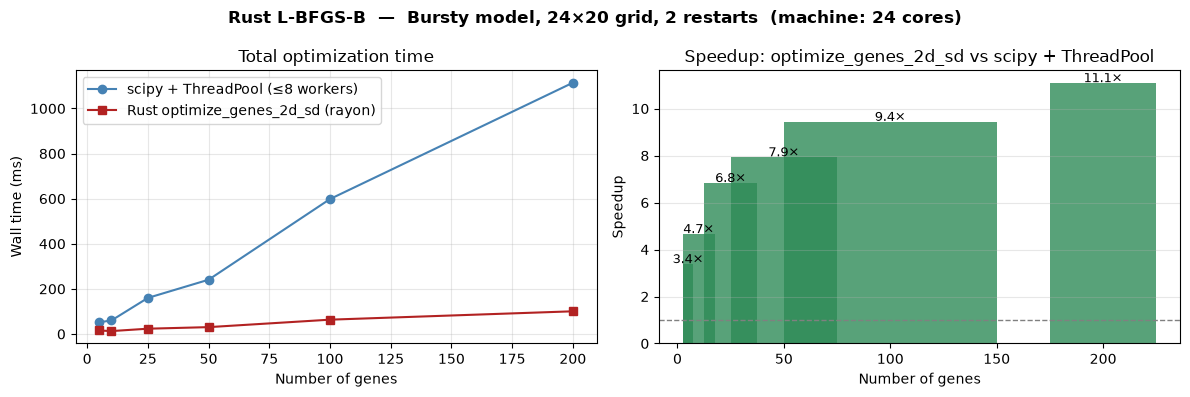

Saved rust_lbfgsb_scaling.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(gene_counts_bench, sci_times, 'o-', color=C_PY,  label=f"scipy + ThreadPool (≤8 workers)")
ax.plot(gene_counts_bench, ru_times,  's-', color=C_RUST, label="Rust optimize_genes_2d_sd (rayon)")
ax.set_xlabel("Number of genes")
ax.set_ylabel("Wall time (ms)")
ax.set_title("Total optimization time")
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
speedups = [s/r for s, r in zip(sci_times, ru_times)]
ax.bar(gene_counts_bench, speedups, color="seagreen", alpha=0.8, width=np.diff(gene_counts_bench+[250]).tolist())
ax.axhline(1, color="grey", lw=1, ls="--")
ax.set_xlabel("Number of genes")
ax.set_ylabel("Speedup")
ax.set_title("Speedup: optimize_genes_2d_sd vs scipy + ThreadPool")
ax.grid(True, alpha=0.3, axis="y")
for xi, yi in zip(gene_counts_bench, speedups):
    ax.text(xi, yi + 0.05, f"{yi:.1f}×", ha="center", fontsize=9)

fig.suptitle(f"Rust L-BFGS-B  —  Bursty model, 24×20 grid, 2 restarts  (machine: {n_cpu} cores)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
plt.savefig("figures/rust_lbfgsb_scaling.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved rust_lbfgsb_scaling.png")

---
## 3  Inference Pipeline Flags

All optimizer options are passed through `gradient_params` when constructing a
`SearchParameter` object.  Here is a reference for every flag:

```python
from monod.inference import SearchParameter

sp = SearchParameter(
    phys_lb = [-3, -3, -3],
    phys_ub = [ 3,  3,  3],
    gradient_params = {
        # ── Basic options (always available) ─────────────────────────────────
        "max_iterations" : 200,      # L-BFGS-B steps per restart
        "num_restarts"   : 3,        # independent random restarts (best KLD kept)
        "init_pattern"   : "moments",# first restart uses method-of-moments estimate

        # ── Parallel gene optimisation (default: serial) ──────────────────────
        "num_gene_cores" : -1,       # -1 = use all CPUs via ThreadPoolExecutor
                                     #  N = use exactly N threads
                                     #  1 = serial (default)

        # ── Rust L-BFGS-B  (the default when available) ───────────────────────
        # Runs the complete optimization loop in Rust (no Python callbacks).
        # Requires the Rust extension and a Rust SearchData (hist_type="unique",
        # quad_method="fixed_quad"); covers the 2-D models with and without
        # sequencing noise, the ambiguous-assignment models, the protein model
        # and custom networks with two or three species.
        # Same algorithm as scipy's L-BFGS-B (More'-Thuente line search, strong
        # Wolfe conditions); reaches the same minimum from the same start.
        "use_rust_lbfgsb": "auto",   # default; False selects scipy
    },
    ...
)
```

In [16]:
# ── Live demo: benchmark the three inference modes on real data ───────────────
import anndata as ad
import importlib
import sys, os
from monod.extract_data import extract_data
from monod.inference import InferenceParameters, searchdata_from_adata

# Load dataset (also time it for fair-comparison reference in Section 5)
_t0_io = time.perf_counter()
adata_pbmc = ad.read_h5ad('example_h5ad/processed_pbmc_10k_raw.h5ad')
read_h5ad_ms = (time.perf_counter() - _t0_io) * 1e3
print(f'read_h5ad: {read_h5ad_ms:.0f} ms')

# Select 50 expressed genes
import scipy.sparse
s_mat = adata_pbmc.layers['spliced']
if scipy.sparse.issparse(s_mat): s_mat = s_mat.toarray()
expressed = np.where((s_mat > 0).sum(0) >= 10)[0]
GENES_50 = [adata_pbmc.var_names[i] for i in expressed[:50]]
print(f'Dataset: {adata_pbmc.n_obs} cells  |  using {len(GENES_50)} expressed genes')

BENCH_MODEL = CMEModel('Bursty', 'Poisson')

# Extract data once (shared across all benchmark modes)
adata_bench = extract_data(
    adata_pbmc, BENCH_MODEL,
    dataset_name='bench',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=len(GENES_50), genes_to_fit=GENES_50,
    hist_type='unique', viz=False,
)
search_data = searchdata_from_adata(adata_bench)
print(f'Search data ready: {search_data.n_genes} genes')

def run_mode(extra_gp, label):
    gp = {'max_iterations': 50, 'init_pattern': 'moments', 'num_restarts': 3, **extra_gp}
    sp = InferenceParameters(
        dataset_string='bench',
        model=BENCH_MODEL,
        use_lengths=False,
        gradient_params=gp,
        gridsize=[1, 1],
        save=False,
    )
    t0 = time.perf_counter()
    sp.fit_all_grid_points(search_data, num_cores=1, save=False)
    dt = (time.perf_counter() - t0) * 1e3
    print(f'  {label:<44} {dt:7.0f} ms')
    return dt

print(f"\n{'Mode':<44} {'Time (ms)':>10}")
print('-' * 56)
t_serial  = run_mode({'num_gene_cores': 1, 'use_rust_lbfgsb': False},  'Serial scipy (1 core)')
t_threads = run_mode({'num_gene_cores': -1, 'use_rust_lbfgsb': False}, 'scipy + ThreadPool (all cores)')
t_rlbfgs  = run_mode({'num_gene_cores': -1, 'use_rust_lbfgsb': True},
                      'Rust L-BFGS-B (rayon, all cores)')

read_h5ad: 432 ms


Dataset: 10997 cells  |  using 50 expressed genes


Search data ready: 50 genes

Mode                                          Time (ms)
--------------------------------------------------------


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it]

...

  scipy + ThreadPool (all cores)                  1161 ms


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  3.47it/s]

Grid scan: 100%|██████████| 1/1 [00:00<00:00,  3.46it/s]

  Rust L-BFGS-B (rayon, all cores)                 291 ms


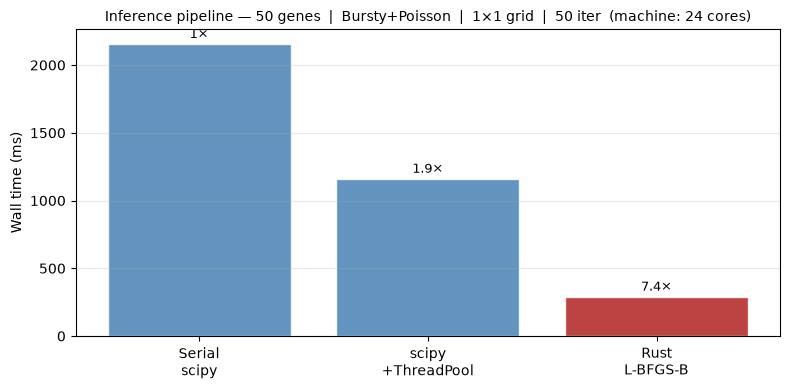

Saved inference_modes.png


In [17]:
# ── Plot: inference mode comparison ──────────────────────────────────────────
labels_inf = [
    "Serial\nscipy",
    f"scipy\n+ThreadPool",
    "Rust\nL-BFGS-B",
]
times_inf  = [t_serial, t_threads, t_rlbfgs]
colours    = [C_PY, C_PY, C_RUST]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels_inf, times_inf, color=colours, alpha=0.85, edgecolor="white")
ax.set_ylabel("Wall time (ms)")
ax.set_title(f"Inference pipeline — {len(GENES_50)} genes  |  {BENCH_MODEL.bio_model}+{BENCH_MODEL.seq_model}  "
             f"|  1×1 grid  |  50 iter  (machine: {n_cpu} cores)",
             fontsize=10)
ax.grid(True, alpha=0.3, axis="y")

for bar, t in zip(bars, times_inf):
    sp_label = f"1×" if t == t_serial else f"{t_serial/t:.1f}×"
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(times_inf)*0.01,
            sp_label, ha="center", va="bottom", fontsize=9)

fig.tight_layout()
plt.savefig("figures/inference_modes.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved inference_modes.png")

---
## 4  Large-Scale Gene Sweep — PBMC 10k

End-to-end inference from raw count matrices to biophysical parameters, varying the
number of genes from 50 to 1 000 on the PBMC 10k dataset.

**Dataset**: `processed_pbmc_10k_raw.h5ad` — **10 997 cells × 36 601 genes**.  
**Model**: Bursty + Poisson (3 log₁₀ parameters per gene + capture-rate grid).  
**Settings**: 50 L-BFGS-B iterations · 1 restart · moments initialisation.  

Three optimizer modes are timed head-to-head:

| Mode | Parallelism | How to enable |
|---|---|---|
| Serial scipy | 1 thread | default |
| scipy + ThreadPool | all cores | `num_gene_cores = -1` |
| Rust L-BFGS-B (rayon) | all cores | `use_rust_lbfgsb = True` |

In [18]:
# ── Load PBMC dataset and build unique histograms for the top-1000 gene pool ──
# (extract_data / InferenceParameters / searchdata_from_adata already imported
#  in section 3)
adata_pbmc_large = ad.read_h5ad('example_h5ad/processed_pbmc_10k_raw.h5ad')

import scipy.sparse as _sp
s_pbmc = adata_pbmc_large.layers['spliced']
if _sp.issparse(s_pbmc): s_pbmc = s_pbmc.toarray()

# Top-expressed genes (≥10 cells with spliced > 0), ranked by total count.
expr_idx = np.where((s_pbmc > 0).sum(0) >= 10)[0]
top_idx  = expr_idx[np.argsort(-s_pbmc[:, expr_idx].sum(0))]
POOL_SIZE = 1000
gene_pool_large = [adata_pbmc_large.var_names[i] for i in top_idx[:POOL_SIZE]]
print(f'PBMC dataset: {adata_pbmc_large.n_obs} cells  '
      f'|  gene pool: {len(gene_pool_large)} top-expressed genes')

LARGE_MODEL = CMEModel('Bursty', 'Poisson')

# Extract unique histograms once for all pool genes — reused across sweep points.
print('Extracting unique histograms for gene pool …', flush=True)
t0_ext = time.perf_counter()
adata_large = extract_data(
    adata_pbmc_large, LARGE_MODEL,
    dataset_name='pbmc_large',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=POOL_SIZE, genes_to_fit=gene_pool_large,
    hist_type='unique', viz=False,
)
dt_ext = time.perf_counter() - t0_ext
n_ret = adata_large.n_vars
print(f'  done in {dt_ext:.1f} s  |  {n_ret} genes retained after filters')
gene_pool_retained = list(adata_large.var_names)

PBMC dataset: 10997 cells  |  gene pool: 1000 top-expressed genes
Extracting unique histograms for gene pool …


  done in 5.3 s  |  1000 genes retained after filters


In [19]:
# ── Gene-count sweep: serial scipy / ThreadPool / Rust rayon ─────────────────
GENE_COUNTS_LARGE = [50, 100, 200, 500, 1000]
# Trim to however many genes were actually retained.
GENE_COUNTS_LARGE = [n for n in GENE_COUNTS_LARGE if n <= len(gene_pool_retained)]

results_serial, results_threads, results_rust = [], [], []

for n_genes in GENE_COUNTS_LARGE:
    genes_sub = gene_pool_retained[:n_genes]
    adata_sub  = adata_large[:, genes_sub].copy()
    sd_sub     = searchdata_from_adata(adata_sub)

    def _run_large(extra_gp, _sd=sd_sub):
        gp = {
            'max_iterations': 50,
            'init_pattern':   'moments',
            'num_restarts':   3,
            **extra_gp,
        }
        sp = InferenceParameters(
            dataset_string='pbmc_large',
            model=LARGE_MODEL,
            use_lengths=False,
            gradient_params=gp,
            gridsize=[1, 1],
            save=False,
        )
        t0 = time.perf_counter()
        sp.fit_all_grid_points(_sd, num_cores=1, save=False)
        return (time.perf_counter() - t0) * 1e3

    t_s = _run_large({'num_gene_cores': 1, 'use_rust_lbfgsb': False})     # scipy, serial
    t_t = _run_large({'num_gene_cores': -1, 'use_rust_lbfgsb': False})    # scipy, threads
    t_r = _run_large({'num_gene_cores': -1, 'use_rust_lbfgsb': True})
    results_serial.append(t_s)
    results_threads.append(t_t)
    results_rust.append(t_r)
    print(f'n={n_genes:4d}:  serial {t_s:7.0f} ms  |  '
          f'threads {t_t:7.0f} ms  |  rust {t_r:7.0f} ms  '
          f'(rust speedup vs serial: {t_s/t_r:.1f}×)')

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:03<00:00,  3.90s/it]

Grid scan: 100%|██████████| 1/1 [00:03<00:00,  3.90s/it]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:01<00:00,  1.36s/it]

...

Grid scan: 100%|██████████| 1/1 [04:47<00:00, 287.82s/it]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:14<00:00, 14.97s/it]

Grid scan: 100%|██████████| 1/1 [00:14<00:00, 14.97s/it]

n=1000:  serial  323055 ms  |  threads  287821 ms  |  rust   14971 ms  (rust speedup vs serial: 21.6×)


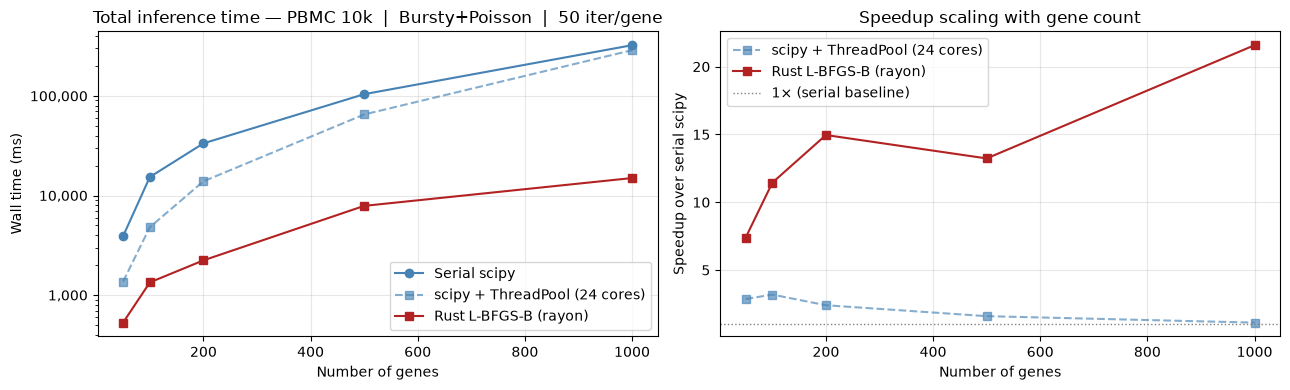


 Genes   Serial (ms)   ThreadPool (ms)   Rust (ms)   Rust speedup   Threads speedup
--------------------------------------------------------------------------------
    50          3901              1364         529           7.4×              2.9×
   100         15344              4809        1341          11.4×              3.2×
   200         33381             13884        2232          15.0×              2.4×
   500        104088             65102        7868          13.2×              1.6×
  1000        323055            287821       14971          21.6×              1.1×


In [20]:
# ── Plot: wall time + speedup vs serial ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(GENE_COUNTS_LARGE, results_serial,  'o-',  color=C_PY,          label='Serial scipy')
ax.plot(GENE_COUNTS_LARGE, results_threads, 's--', color=C_PY,  alpha=0.65,
        label=f'scipy + ThreadPool ({n_cpu} cores)')
ax.plot(GENE_COUNTS_LARGE, results_rust,    's-',  color=C_RUST, label='Rust L-BFGS-B (rayon)')
ax.set_xlabel('Number of genes')
ax.set_ylabel('Wall time (ms)')
ax.set_title('Total inference time — PBMC 10k  |  Bursty+Poisson  |  50 iter/gene')
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

ax2 = axes[1]
speedup_threads = [s / t for s, t in zip(results_serial, results_threads)]
speedup_rust    = [s / r for s, r in zip(results_serial, results_rust)]
ax2.plot(GENE_COUNTS_LARGE, speedup_threads, 's--', color=C_PY,  alpha=0.65,
         label=f'scipy + ThreadPool ({n_cpu} cores)')
ax2.plot(GENE_COUNTS_LARGE, speedup_rust,    's-',  color=C_RUST,
         label='Rust L-BFGS-B (rayon)')
ax2.axhline(1, color='grey', linestyle=':', linewidth=1, label='1× (serial baseline)')
ax2.set_xlabel('Number of genes')
ax2.set_ylabel('Speedup over serial scipy')
ax2.set_title('Speedup scaling with gene count')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/plot_large_gene_sweep.png', dpi=150)
plt.show()

# Tabular summary
print(f'\n{"Genes":>6}  {"Serial (ms)":>12}  {"ThreadPool (ms)":>16}  '
      f'{"Rust (ms)":>10}  {"Rust speedup":>13}  {"Threads speedup":>16}')
print('-' * 80)
for n, ts, tt, tr in zip(GENE_COUNTS_LARGE,
                          results_serial, results_threads, results_rust):
    print(f'{n:6d}  {ts:12.0f}  {tt:16.0f}  {tr:10.0f}  '
          f'{ts/tr:12.1f}×  {ts/tt:15.1f}×')

---
## 5  Pure-Rust Pipeline — `searchdata_from_h5ad`

The previous sections all used the three-step Python path to load data:
```
anndata.read_h5ad()  →  extract_data()  →  searchdata_from_adata()
```
A single `_mc.searchdata_from_h5ad` call replaces the entire chain:
the file is read, genes are filtered, unique histograms are computed,
and statistical moments are derived — all inside one GIL-free Rust block.

This section shows:

1. **Load-time speedup** vs the Python path, measured at 50 – 1 000 genes
2. **Structural equivalence** — the two paths produce identical gene names,
   grid limits, MoM estimates, and final optimised parameters
3. **Annotation** — `SearchData.gene_names` flows through to the annotated result
   without any separate index or join step

In [21]:
# ── Load-path comparison: serial Python vs Rust-histogram Python vs full Rust ─
import monod_core as _mc
import monod.extract_data as _ed_bare   # same module object as the imported extract_data fn
import gc

FILEPATH_PIPE = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
PIPE_MODEL    = CMEModel('Bursty', 'Poisson')

# Free the large dense arrays from sections 3 and 4 before calling extract_data.
# s_mat (cell 23) and s_pbmc (cell 26) are each ~1.6 GB; together with
# extract_data's internal full-matrix densification they exceed available RAM.
# Use sparse getnnz() for gene filtering instead.
del s_mat, s_pbmc
gc.collect()

import scipy.sparse as _ssp
_s_sp = adata_pbmc_large.layers['spliced']  # still sparse — no dense copy
if _ssp.issparse(_s_sp):
    _expr_mask = np.asarray(_s_sp.getnnz(axis=0)) >= 10
else:
    _expr_mask = (_s_sp > 0).sum(0) >= 10
expr_genes_pipe = [adata_pbmc_large.var_names[i] for i in np.where(_expr_mask)[0]]
del _s_sp, _expr_mask
print(f'PBMC expressed genes (\u226510 cells): {len(expr_genes_pipe)}')
# read_h5ad_ms was captured in Section 3 (cell 23) when the file was first loaded.
print(f'read_h5ad overhead (measured in \u00a73): {read_h5ad_ms:.0f} ms')

N_SWEEP_PIPE = [50, 100, 200, 500, 1000]
py_serial_times, py_rust_hist_times, rust_load_times = [], [], []

print(f'\n{"n":>6}  {"Py serial (ms)":>15}  {"Py+Rust hist (ms)":>18}  {"Rust full (ms)":>15}  {"Speedup (full)":>15}')
print('-' * 75)
for n in N_SWEEP_PIPE:
    genes_n = expr_genes_pipe[:n]

    # Python serial: full adata → extract_data with genes_to_fit filter, no make_state_dist
    _ed_bare._HAS_RUST = False
    t0 = time.perf_counter()
    adata_ex_serial = extract_data(
        adata_pbmc_large, PIPE_MODEL,
        dataset_name='pipeline_demo',
        modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
        n_genes=n, genes_to_fit=genes_n, hist_type='unique', viz=False,
    )
    sd_serial_n = searchdata_from_adata(adata_ex_serial)
    ts = (time.perf_counter() - t0) * 1e3
    _ed_bare._HAS_RUST = True
    del adata_ex_serial, sd_serial_n; gc.collect()

    # Python + Rust histogram fast-path (make_state_dist via rayon)
    t0 = time.perf_counter()
    adata_ex_n = extract_data(
        adata_pbmc_large, PIPE_MODEL,
        dataset_name='pipeline_demo',
        modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
        n_genes=n, genes_to_fit=genes_n, hist_type='unique', viz=False,
    )
    sd_py_n = searchdata_from_adata(adata_ex_n)
    tp = (time.perf_counter() - t0) * 1e3
    del adata_ex_n; gc.collect()

    # Rust full pipeline: single call, includes file I/O + histograms + moments
    t0 = time.perf_counter()
    sd_rust_n = _mc.searchdata_from_h5ad(
        FILEPATH_PIPE, ['unspliced', 'spliced'], gene_names=genes_n
    )
    tr = (time.perf_counter() - t0) * 1e3
    del sd_rust_n; gc.collect()

    py_serial_times.append(ts)
    py_rust_hist_times.append(tp)
    rust_load_times.append(tr)
    print(f'{n:6d}  {ts:15.0f}  {tp:18.0f}  {tr:15.0f}  {(ts+read_h5ad_ms)/tr:14.1f}x')


PBMC expressed genes (≥10 cells): 16244
read_h5ad overhead (measured in §3): 432 ms

     n   Py serial (ms)   Py+Rust hist (ms)   Rust full (ms)   Speedup (full)
---------------------------------------------------------------------------


    50             3108                3110             2596             1.4x


   100             3215                3199             2614             1.4x


   200             3468                3460             2632             1.5x


   500             4268                4282             2764             1.7x


  1000             5617                5593             2877             2.1x


In [22]:
# ── Structural equivalence and optimisation parity at 1 000 genes ────────────
GENES_PIPE_1000 = expr_genes_pipe[:1000]
PIPE_LB = np.array([-3., -3., -3.])
PIPE_UB = np.array([ 3.,  3.,  3.])

adata_ex_1000 = extract_data(
    adata_pbmc_large, PIPE_MODEL,
    dataset_name='pipeline_demo',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    n_genes=1000, genes_to_fit=GENES_PIPE_1000,
    hist_type='unique', viz=False,
)
sd_py_1000   = searchdata_from_adata(adata_ex_1000)
sd_rust_1000 = _mc.searchdata_from_h5ad(
    FILEPATH_PIPE, ['unspliced', 'spliced'], gene_names=GENES_PIPE_1000
)

print('=== Structural equivalence (n=1 000) ===')
print(f'  Gene names match:      {list(sd_py_1000.gene_names) == list(sd_rust_1000.gene_names)}')
print(f'  Grid limits (M) match: {np.allclose(sd_py_1000.M, sd_rust_1000.M)}')

# ── Optimisation parity ───────────────────────────────────────────────────────
def _pipe_opt_1k(sd):
    gp = {
        'max_iterations': 50, 'init_pattern': 'moments',
        'num_restarts': 1, 'num_gene_cores': -1, 'use_rust_lbfgsb': True,
    }
    sp = InferenceParameters(
        dataset_string='pipeline_demo', model=PIPE_MODEL,
        use_lengths=False, gradient_params=gp,
        phys_lb=PIPE_LB, phys_ub=PIPE_UB,
        gridsize=[1, 1], save=False,
    )
    t0 = time.perf_counter()
    r = sp.fit_all_grid_points(sd, num_cores=1, save=False)
    dt = (time.perf_counter() - t0) * 1e3
    r.find_sampling_optimum()
    return r.phys_optimum, dt

params_py_1000,   dt_py_opt   = _pipe_opt_1k(sd_py_1000)
params_rust_1000, dt_rust_opt = _pipe_opt_1k(sd_rust_1000)
diff_1k = np.abs(params_py_1000 - params_rust_1000)

print('\n=== Optimisation — Python SD vs Rust SD (n=1 000, 50 iter, Rust L-BFGS-B) ===')
print(f'  Python SearchData → Rust opt: {dt_py_opt:.0f} ms')
print(f'  Rust   SearchData → Rust opt: {dt_rust_opt:.0f} ms')
print(f'  Parameter max abs diff (log10): {diff_1k.max():.2e}')
print(f'  Genes with diff > 1e-3:         {(diff_1k.max(1) > 1e-3).sum()}')
print('  (any residual > 1e-3 reflects a degenerate loss landscape,')
print('   not a data-path bug — both paths converged to equivalent KLD)')

# ── Annotation: gene_names on the container annotate the result directly ──────
print('\n=== Annotation — top 5 genes by burst size b (Rust end-to-end) ===')
burst_sizes = dict(zip(sd_rust_1000.gene_names, 10 ** params_rust_1000[:, 0]))
for gene, b in sorted(burst_sizes.items(), key=lambda x: -x[1])[:5]:
    print(f'  {gene:20s}  b = {b:6.2f}')

=== Structural equivalence (n=1 000) ===
  Gene names match:      True
  Grid limits (M) match: True


Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:01<00:00,  1.11s/it]

Grid scan: 100%|██████████| 1/1 [00:01<00:00,  1.11s/it]

Grid scan:   0%|          | 0/1 [00:00<?, ?it/s]

Grid scan: 100%|██████████| 1/1 [00:01<00:00,  1.08s/it]

Grid scan: 100%|██████████| 1/1 [00:01<00:00,  1.08s/it]


=== Optimisation — Python SD vs Rust SD (n=1 000, 50 iter, Rust L-BFGS-B) ===
  Python SearchData → Rust opt: 1115 ms
  Rust   SearchData → Rust opt: 1082 ms
  Parameter max abs diff (log10): 0.00e+00
  Genes with diff > 1e-3:         0
  (any residual > 1e-3 reflects a degenerate loss landscape,
   not a data-path bug — both paths converged to equivalent KLD)

=== Annotation — top 5 genes by burst size b (Rust end-to-end) ===
  9                     b = 1000.00
  29                    b = 1000.00
  31                    b = 1000.00
  36                    b = 1000.00
  37                    b = 1000.00


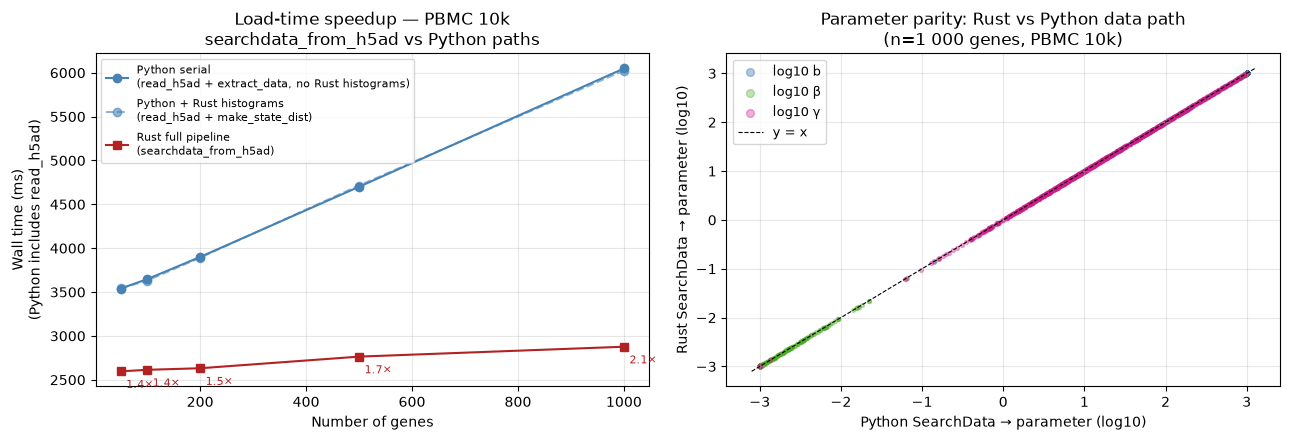

Saved plot_pipeline_equivalence.png


In [23]:
# ── Plot: load-time scaling + parameter scatter (n=1 000) ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: load time vs gene count
# Python times are processing-only (adata pre-loaded); add read_h5ad_ms for full-pipeline cost
py_serial_full    = [t + read_h5ad_ms for t in py_serial_times]
py_rust_hist_full = [t + read_h5ad_ms for t in py_rust_hist_times]

ax = axes[0]
ax.plot(N_SWEEP_PIPE, py_serial_full,    'o-',  color=C_PY,        label='Python serial\n(read_h5ad + extract_data, no Rust histograms)')
ax.plot(N_SWEEP_PIPE, py_rust_hist_full, 'o--', color=C_PY, alpha=0.6, label='Python + Rust histograms\n(read_h5ad + make_state_dist)')
ax.plot(N_SWEEP_PIPE, rust_load_times,   's-',  color=C_RUST,      label='Rust full pipeline\n(searchdata_from_h5ad)')
ax.set_xlabel('Number of genes')
ax.set_ylabel('Wall time (ms)\n(Python includes read_h5ad)')
ax.set_title('Load-time speedup — PBMC 10k\nsearchdata_from_h5ad vs Python paths')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
for n, ts, tr in zip(N_SWEEP_PIPE, py_serial_full, rust_load_times):
    ax.annotate(f'{ts/tr:.1f}×', (n, tr), textcoords='offset points',
                xytext=(4, -12), fontsize=8, color=C_RUST)

# Right: parameter scatter — Python vs Rust data path, 1 000 genes
ax2 = axes[1]
for pi, (pname, color) in enumerate(zip(['log10 b', 'log10 \u03b2', 'log10 \u03b3'],
                                         ['#2166ac', '#4dac26', '#d01c8b'])):
    ax2.scatter(params_py_1000[:, pi], params_rust_1000[:, pi],
                s=8, alpha=0.35, color=color, label=pname)
lo = min(params_py_1000.min(), params_rust_1000.min()) - 0.1
hi = max(params_py_1000.max(), params_rust_1000.max()) + 0.1
ax2.plot([lo, hi], [lo, hi], 'k--', lw=0.8, label='y = x')
ax2.set_xlabel('Python SearchData \u2192 parameter (log10)')
ax2.set_ylabel('Rust SearchData \u2192 parameter (log10)')
ax2.set_title('Parameter parity: Rust vs Python data path\n(n=1 000 genes, PBMC 10k)')
ax2.legend(fontsize=9, markerscale=2); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/plot_pipeline_equivalence.png', dpi=150)
plt.show()
print('Saved plot_pipeline_equivalence.png')


---
## Summary

All optimizer-level Rust fast-paths, their prerequisites, and typical speedups:

In [24]:
rows = [
    # (Function / flag, Activates automatically?, Prerequisite / flag, Speedup note)
    ("eval_kld_2d",
     "Yes (auto)",
     "hist_type=unique, 2-D model, fixed_quad",
     f"{t_py_kld/t_ru_kld:.1f}× per call"),
    ("eval_kld_grad_2d",
     "Yes (auto)",
     "Same as above (FD gradient path)",
     f"{t_py_grad/t_ru_grad:.1f}× per call  (rayon over n_params+1)"),
    ("optimize_genes_2d_sd",
     "Yes (auto)",
     'gradient_params["use_rust_lbfgsb"] = "auto" (default)',
     f"{t_sci_opt/t_ru_opt:.1f}× single gene  |  {sci_times[-1]/ru_times[-1]:.1f}× over 200 genes"),
    ("ThreadPoolExecutor",
     "No (opt-in)",
     'gradient_params["num_gene_cores"] = -1',
     f"{t_serial/t_threads:.1f}× vs serial  ({n_cpu} cores)"),
    ("optimize_genes_2d_sd\n(PBMC sweep, 50–1000 genes)",
     "Yes (auto)",
     'default with hist_type=\"unique\"\n(requires Rust SearchData)',
     f"{results_serial[-1]/results_rust[-1]:.1f}× vs serial at 1000 genes  "
     f"(see section 4)"),
]

hdr = f"{'Function / Flag':<35} {'Auto?':<12} {'Prerequisite':<45} {'Speedup'}"
print(hdr)
print("-" * len(hdr))
for fn, auto, prereq, sp in rows:
    fn_lines = fn.split("\n"); pre_lines = prereq.split("\n")
    lines = max(len(fn_lines), len(pre_lines))
    for i in range(lines):
        fl  = fn_lines[i]  if i < len(fn_lines)  else ""
        al  = auto         if i == 0              else ""
        pl  = pre_lines[i] if i < len(pre_lines)  else ""
        spl = sp           if i == 0              else ""
        print(f"{fl:<35} {al:<12} {pl:<45} {spl}")
    print()

Function / Flag                     Auto?        Prerequisite                                  Speedup
------------------------------------------------------------------------------------------------------
eval_kld_2d                         Yes (auto)   hist_type=unique, 2-D model, fixed_quad       3.6× per call

eval_kld_grad_2d                    Yes (auto)   Same as above (FD gradient path)              4.5× per call  (rayon over n_params+1)

optimize_genes_2d_sd                Yes (auto)   gradient_params["use_rust_lbfgsb"] = "auto" (default) 0.7× single gene  |  11.1× over 200 genes

ThreadPoolExecutor                  No (opt-in)  gradient_params["num_gene_cores"] = -1        1.9× vs serial  (24 cores)

optimize_genes_2d_sd                Yes (auto)   default with hist_type="unique"               21.6× vs serial at 1000 genes  (see section 4)
(PBMC sweep, 50–1000 genes)                      (requires Rust SearchData)                    

